# 01 — METR-LA data understanding

The real METR-LA file has been supplied and copied unchanged into `data/raw/metr-la.h5`; `load_context` verifies its recorded checksum before analysis. Executing these cells computes findings from that artifact. The notebook metadata records the actual interpreter, package versions and execution method. Report and metadata outputs can be regenerated from the same raw file.

This is Person A's descriptive Phase 1 EDA. Raw bytes remain unchanged. Exact zeros, negative values and nonfinite readings are unavailable in the separate valid-speed view; positive near-zero speeds remain observed. Speed units and timestamp timezone are unverified: axes use source units and the stored clock. Whole-period EDA is descriptive and must not become fitted model preprocessing or held-out sensor selection.

The [execution plan](../reports/person_a_plan.md), [source evidence](../reports/data_sources.md) and [Person B contract](../reports/person_b_handoff.md) explain scope and limitations.

## Load the canonical context

Root discovery supports opening this notebook from the project root or `notebooks/`. `load_context` checks provenance and file hashes before reading the table. Graph information is inspected only to verify dataset identity/order; no graph values become forecasting inputs.

In [1]:
from pathlib import Path
import os
import sys
os.environ["MPLBACKEND"] = "Agg"
import matplotlib
matplotlib.use("Agg", force=True)

candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next(
    (candidate for candidate in candidates
     if (candidate / "src/data/run_person_a.py").is_file()
     and (candidate / "configs/data_quality.yaml").is_file()),
    None,
)
if ROOT is None:
    raise RuntimeError("Open this notebook from the project root or its notebooks directory.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".mplconfig"))

import numpy as np
import pandas as pd
from IPython.display import Image, JSON, Markdown, display
from src.data.run_person_a import load_context, write_analysis_outputs
from src.data.quality import DEFAULT_CONFIG, analyze_frame

print("Project root:", ROOT)

Project root: /Users/pankajbaid/projects/AML/traffic-flow-capstone


In [2]:
# Verifies all recorded raw-file checksums, reads one HDF5 table and loads
# trusted copied graph metadata. Missing speed data is an explicit error.
context = load_context(ROOT)
df = context["df"]
quality_config = {
    key: value for key, value in context["config"].items()
    if key in DEFAULT_CONFIG
}
analysis = analyze_frame(
    df=df,
    locations=context["locations"],
    graph_sensor_ids=context["graph_sensor_ids"],
    adjacency=context["adjacency"],
    config=quality_config,
)
valid = analysis["valid_speed"]
summary = analysis["summary"]
print("Validation status:", summary["validation_status"])
print("Raw shape:", df.shape)
assert valid.index.equals(df.index) and valid.columns.equals(df.columns)

Validation status: warning
Raw shape: (34272, 207)


## Dimensions, coverage and temporal structure

The following are computed from the actual artifact. Expected benchmark characteristics are reference checks, not replacements for observed results. Missing timestamp rows are distinct from missing cells at existing timestamps.

In [3]:
display(pd.Series(summary["dimensions"], name="measured_value").to_frame())
display(pd.Series(summary["timestamp_validation"], name="measured_value").to_frame())
display(pd.Series(summary["graph_validation"], name="measured_value").to_frame())
display(df.head())
display(df.tail())

,measured_value
timestamps,34272
unique_timestamps,34272
sensors,207
observed_cells,7094304
expected_timestamps,34272
expected_grid_cells,7094304
missing_timestamp_cells,0


,measured_value
start,2012-03-01T00:00:00
end,2012-06-27T23:55:00
timezone,None
timezone_note,Naive source timestamps; no timezone inferred.
expected_sampling_minutes,5.0
modal_sampling_minutes,5.0
duplicate_rows,0
chronologically_ordered,True
missing_timestamp_count,0
missing_timestamps,[]


,measured_value
sensor_ids_provided,True
adjacency_provided,True
used_as_features,False
sensor_count,207
duplicate_sensor_ids,0
same_sensor_set,True
same_sensor_order,True
missing_sensor_ids,[]
extra_sensor_ids,[]
adjacency_shape,"[207, 207]"


,773869,767541,767542,717447,717446,717445,773062,767620,737529,717816,765604,767471,716339,773906,765273,716331,771667,716337,769953,769402,769403,769819,769405,716941,717578,716960,717804,767572,767573,773012,773013,764424,769388,716328,717819,769941,760987,718204,718045,769418,...,717582,717583,717580,716949,717587,772178,717585,716939,768469,764101,767554,773975,773974,717510,717513,717825,767495,767494,717821,717823,717458,717459,769926,764858,717450,717452,717453,759772,717456,771673,772167,769372,774204,769806,717590,717592,717595,772168,718141,769373
2012-03-01 00:00:00,64.375000,67.625000,67.125000,61.500000,66.875000,68.750000,65.125,67.125,59.625000,62.750000,55.500000,66.500000,64.250000,68.500000,60.375000,67.500000,37.75,63.125000,59.750000,62.125000,67.250000,41.250000,54.625000,58.125000,65.125000,64.250000,61.250000,62.750000,66.875000,47.375000,57.000000,67.750000,65.125,66.875000,64.000000,62.000000,64.375,60.750000,60.750,62.375000,...,68.250000,62.000000,64.500000,58.375000,64.500000,63.625000,63.750000,53.625000,69.875000,64.750000,62.375000,64.750000,52.125000,61.625000,63.000000,67.142857,67.625000,63.875000,63.125000,63.375000,64.125000,66.875000,69.875,67.750000,62.000000,66.750000,57.625000,52.625000,69.000000,43.500000,45.625000,65.500,64.500000,66.428571,66.875,59.375000,69.000000,59.250000,69.000000,61.875
2012-03-01 00:05:00,62.666667,68.555556,65.444444,62.444444,64.444444,68.111111,65.000,65.000,57.444444,63.333333,58.777778,58.444444,66.444444,65.444444,56.111111,65.444444,39.00,63.777778,63.111111,66.111111,65.777778,56.777778,50.777778,56.222222,66.888889,54.444444,67.888889,61.555556,67.555556,46.777778,67.777778,67.888889,68.000,67.444444,66.444444,67.222222,63.000,64.333333,64.000,61.888889,...,66.777778,66.555556,67.333333,55.333333,66.555556,66.555556,65.777778,59.888889,66.888889,67.444444,62.222222,62.222222,52.333333,47.666667,67.111111,64.500000,69.111111,63.888889,60.444444,65.777778,63.888889,69.333333,63.000,67.666667,67.333333,66.666667,65.777778,51.666667,69.111111,39.888889,50.666667,69.875,66.666667,58.555556,62.000,61.111111,64.444444,55.888889,68.444444,62.875
2012-03-01 00:10:00,64.000000,63.750000,60.000000,59.000000,66.500000,66.250000,64.500,64.250,63.875000,65.375000,61.375000,62.375000,64.750000,65.250000,61.875000,67.875000,35.25,63.875000,35.625000,65.000000,69.125000,49.125000,55.625000,59.125000,67.875000,63.125000,63.000000,64.500000,59.000000,47.750000,61.571429,66.500000,68.500,65.000000,66.250000,51.250000,63.875,64.875000,65.625,64.625000,...,64.000000,67.375000,65.250000,58.125000,64.625000,67.375000,66.750000,56.000000,68.750000,65.625000,61.000000,63.500000,56.125000,61.375000,64.125000,66.000000,68.625000,67.250000,64.000000,66.875000,65.000000,65.500000,54.875,68.750000,67.375000,65.750000,56.250000,49.375000,67.250000,38.250000,44.125000,69.000,56.500000,59.250000,68.125,62.500000,65.625000,61.375000,69.857143,62.000
2012-03-01 00:15:00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000,0.000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000,0.000000,0.000000,0.000000,0.000,0.000000,0.000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000,0.000000,0.000000,0.000,0.000000,0.000000,0.000000,0.000000,0.000
2012-03-01 00:20:00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000,0.000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000,0.000000,0.000000,0.000000,0.000,0.0000

,773869,767541,767542,717447,717446,717445,773062,767620,737529,717816,765604,767471,716339,773906,765273,716331,771667,716337,769953,769402,769403,769819,769405,716941,717578,716960,717804,767572,767573,773012,773013,764424,769388,716328,717819,769941,760987,718204,718045,769418,...,717582,717583,717580,716949,717587,772178,717585,716939,768469,764101,767554,773975,773974,717510,717513,717825,767495,767494,717821,717823,717458,717459,769926,764858,717450,717452,717453,759772,717456,771673,772167,769372,774204,769806,717590,717592,717595,772168,718141,769373
2012-06-27 23:35:00,65.000000,65.888889,68.555556,61.666667,0.0,54.555556,62.444444,63.333333,59.222222,65.333333,61.444444,64.777778,63.444444,65.222222,60.222222,64.333333,0.0,65.777778,49.666667,65.222222,66.555556,44.111111,50.555556,60.333333,65.222222,62.000000,61.000000,61.333333,68.111111,66.888889,65.888889,62.888889,65.555556,66.333333,66.777778,40.666667,58.222222,66.222222,64.000,63.888889,...,66.777778,65.666667,66.333333,60.555556,64.000000,65.666667,64.333333,53.444444,66.222222,68.777778,63.111111,64.888889,54.777778,66.222222,64.888889,66.111111,68.444444,65.444444,63.333333,66.777778,63.666667,68.333333,59.111111,67.777778,65.555556,66.222222,57.222222,53.444444,69.000000,0.0,52.888889,69.000000,65.111111,55.666667,66.333333,62.444444,66.777778,64.888889,69.666667,62.333333
2012-06-27 23:40:00,61.375000,65.625000,66.500000,62.750000,0.0,50.500000,62.000000,67.000000,65.250000,67.125000,62.875000,65.375000,63.125000,66.250000,63.250000,64.250000,0.0,66.125000,45.125000,62.625000,67.625000,52.250000,55.000000,59.125000,58.750000,61.875000,59.500000,63.000000,66.625000,65.875000,64.500000,62.875000,67.625000,63.750000,68.125000,52.500000,54.125000,66.375000,57.625,53.500000,...,65.250000,67.375000,66.750000,55.250000,67.000000,65.625000,67.250000,56.500000,62.750000,62.000000,63.000000,63.500000,52.500000,66.500000,65.000000,67.714286,68.500000,65.500000,66.500000,64.625000,64.875000,69.625000,50.250000,68.875000,63.000000,67.375000,64.625000,59.125000,68.750000,0.0,54.000000,69.250000,60.125000,60.500000,67.250000,59.375000,66.000000,61.250000,69.000000,62.000000
2012-06-27 23:45:00,67.000000,59.666667,69.555556,61.000000,0.0,44.777778,64.222222,63.777778,59.777778,57.666667,64.444444,64.666667,64.444444,66.444444,55.777778,59.000000,0.0,64.444444,52.222222,63.000000,66.666667,56.555556,53.555556,61.333333,66.777778,58.666667,58.888889,63.444444,65.666667,68.000000,65.222222,67.555556,67.111111,66.888889,68.111111,55.000000,65.222222,63.333333,65.000,61.444444,...,66.444444,66.888889,65.555556,55.555556,65.000000,67.222222,65.111111,52.222222,61.888889,68.222222,62.888889,64.333333,53.222222,65.888889,64.444444,68.333333,66.888889,66.888889,63.000000,67.888889,66.111111,69.111111,61.125000,66.444444,60.333333,65.333333,66.777778,48.222222,69.777778,0.0,51.333333,67.888889,64.333333,57.000000,66.000000,62.666667,68.666667,63.333333,67.444444,61.222222
2012-06-27 23:50:00,66.750000,62.250000,66.000000,59.625000,0.0,53.000000,64.285714,64.125000,60.875000,66.250000,61.375000,64.875000,64.875000,62.750000,42.500000,65.625000,0.0,62.375000,53.375000,64.875000,66.625000,51.375000,50.875000,55.875000,68.500000,62.625000,59.250000,61.750000,69.625000,68.000000,64.875000,66.750000,67.375000,65.000000,65.125000,54.625000,54.250000,66.250000,69.600,61.125000,...,65.500000,69.875000,69.250000,55.125000,68.750000,66.750000,67.500000,60.750000,68.875000,67.125000,57.875000,62.375000,53.250000,66.428571,64.142857,66.857143,67.625000,64.625000,63.875000,64.000000,67.375000,69.125000,63.125000,67.500000,66.750000,67.125000,66.875000,55.625000,69.625000,0.0,51.125000,69.375000,61.625000,60.500000,65.625000,66.375000,69.500000,63.000000,67.875000,63.500000
2012-06-27 23:55:00,65.111111,66.888889,66.777778,61.222222,0.0,49.555556,65.777778,65.111111,63.000000,61.666667,61.111111,64.666667,64.333333,67.111111,65.333333,65.888889,0.0,65.111111,54.777778,62.555556,68.111111,60.77

## Raw versus quality-masked speed

The raw distribution below includes finite zeros and negative readings. The comparison view retains finite positive speeds only. Neither table nor histogram changes the canonical raw file. Masking indicates benchmark unavailability; it does not establish the physical cause of a zero.

,raw_finite_including_zero,valid_positive_only
count,7.094304e+06,6.519002e+06
mean,5.371902e+01,5.845973e+01
std,2.026143e+01,1.302360e+01
min,0.000000e+00,3.333333e-01
5%,0.000000e+00,2.562500e+01
25%,5.312500e+01,5.712500e+01
50%,6.244444e+01,6.322222e+01
75%,6.625000e+01,6.650000e+01
95%,6.887500e+01,6.888889e+01
max,7.000000e+01,7.000000e+01


,measured_cells
missing_nan,0
infinite,0
zero,575302
negative_finite,0
valid_positive_finite,6519002
invalid_total,575302


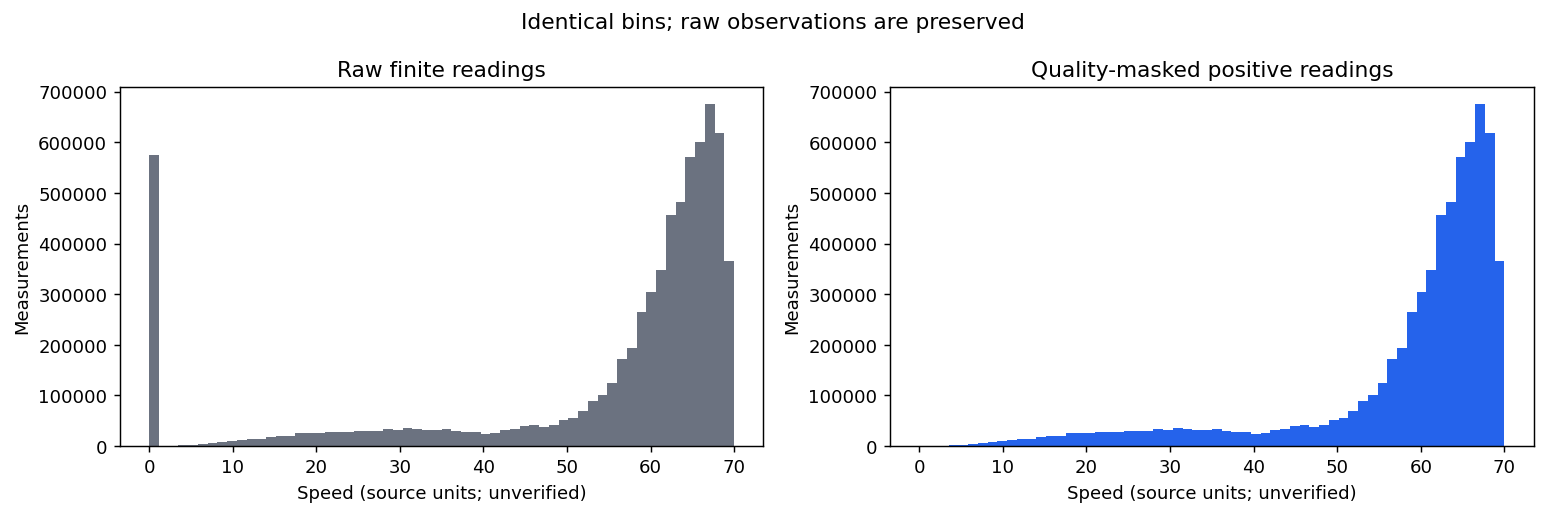

In [4]:
raw_values = df.to_numpy(dtype=float, na_value=np.nan).ravel()
raw_finite = raw_values[np.isfinite(raw_values)]
valid_values = valid.to_numpy(dtype=float).ravel()
valid_positive = valid_values[np.isfinite(valid_values)]
distribution_summary = pd.concat(
    {
        "raw_finite_including_zero": pd.Series(raw_finite).describe(
            percentiles=[.05, .25, .5, .75, .95]
        ),
        "valid_positive_only": pd.Series(valid_positive).describe(
            percentiles=[.05, .25, .5, .75, .95]
        ),
    },
    axis=1,
)
display(distribution_summary)
display(pd.Series(summary["value_counts"], name="measured_cells").to_frame())

from io import BytesIO
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True)
if raw_finite.size:
    edges = np.histogram_bin_edges(raw_finite, bins=60)
    axes[0].hist(raw_finite, bins=edges, color="#6b7280")
    axes[1].hist(valid_positive, bins=edges, color="#2563eb")
else:
    for ax in axes:
        ax.text(.5, .5, "No finite raw measurements", transform=ax.transAxes,
                ha="center", va="center")
for ax, label in zip(axes, ["Raw finite readings", "Quality-masked positive readings"]):
    ax.set(title=label, xlabel="Speed (source units; unverified)", ylabel="Measurements")
fig.suptitle("Identical bins; raw observations are preserved")
fig.tight_layout()
image_buffer = BytesIO()
fig.savefig(image_buffer, format="png", dpi=130, bbox_inches="tight")
display(Image(data=image_buffer.getvalue()))
plt.close(fig)
del raw_values, raw_finite, valid_values, valid_positive

## Generate the ten requested EDA figures

All sensors enter the sensor-distribution and variance plots. Profiles pool valid sensor cells; missing observations can bias the apparent traffic pattern. Missingness plots use existing timestamps and the quality notebook audits absent timestamps separately. Peak windows are weekdays `[07:00, 10:00)` and `[16:00, 19:00)` on the stored clock.

Structural failures block the canonical handoff. Descriptive EDA can still inspect missing timestamps or graph-coverage problems when timestamps are chronological and unique. Plotting is deferred for duplicate or unordered timestamps; no automatic sorting, sensor removal, filling or deduplication is performed here.

In [5]:
from src.data.eda import generate_eda

figure_paths = {}
if not df.index.is_monotonic_increasing or not df.index.is_unique:
    display(Markdown("**EDA generation deferred: timestamps must be chronological and unique.**"))
    display(JSON({"issues": summary["issues"]}))
else:
    figure_paths = generate_eda(df, analysis, ROOT / "figures")
    expected_figures = {
        "overall_speed_distribution", "sensor_speed_distribution",
        "average_speed_by_hour", "average_speed_by_day_of_week",
        "weekday_weekend_profile", "morning_evening_congestion",
        "missingness_by_sensor", "missingness_over_time",
        "sensor_variance_distribution", "sample_sensor_timeseries",
    }
    assert set(figure_paths) == expected_figures, "The required EDA artifact set is incomplete."
    print("Generated EDA figures:", len(figure_paths))

Generated EDA figures: 10


### Overall speed distribution

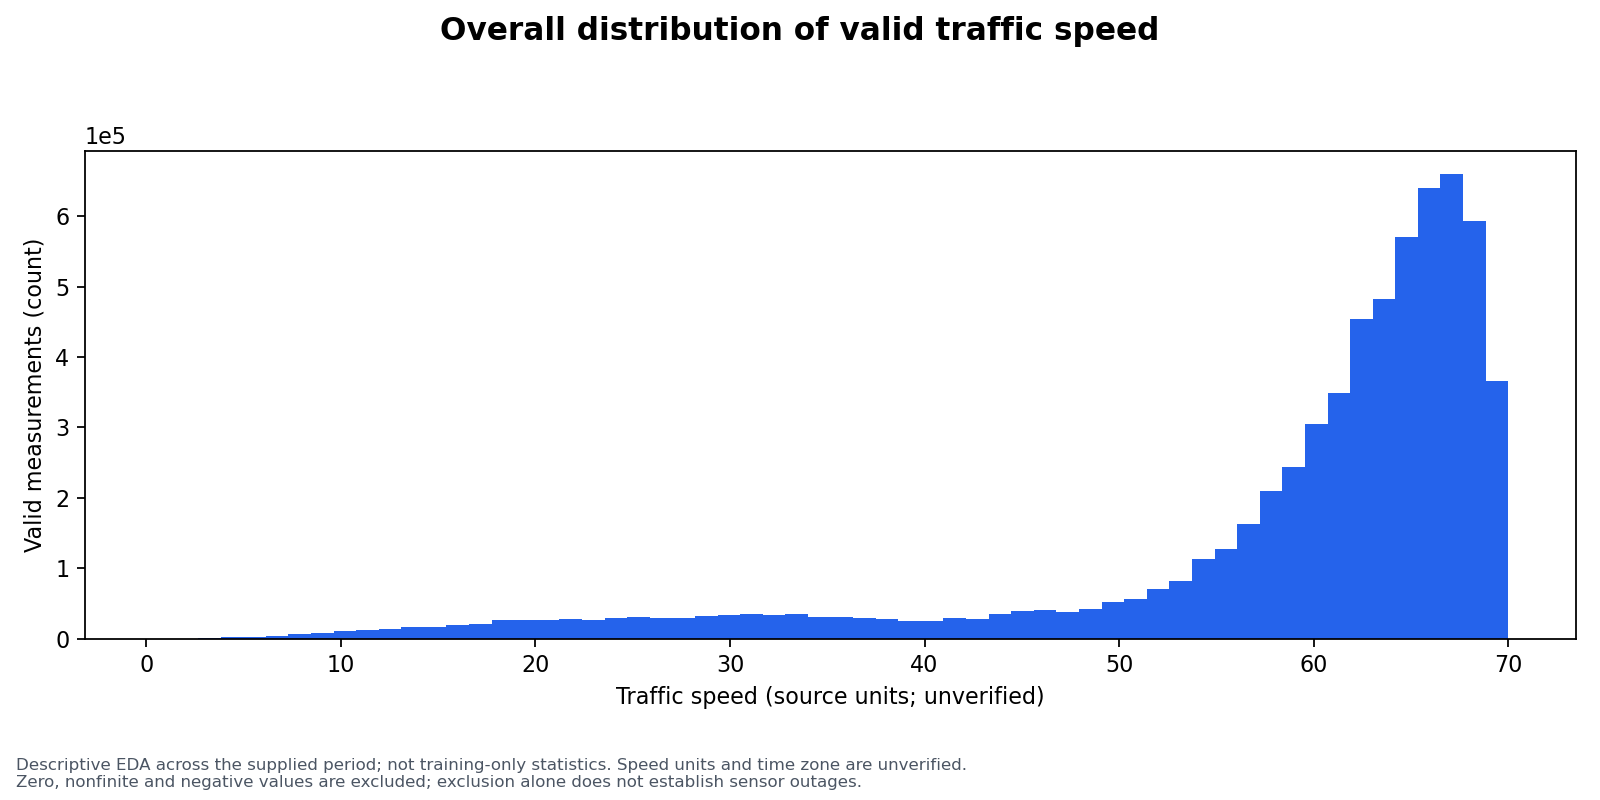

### Sensor speed distribution

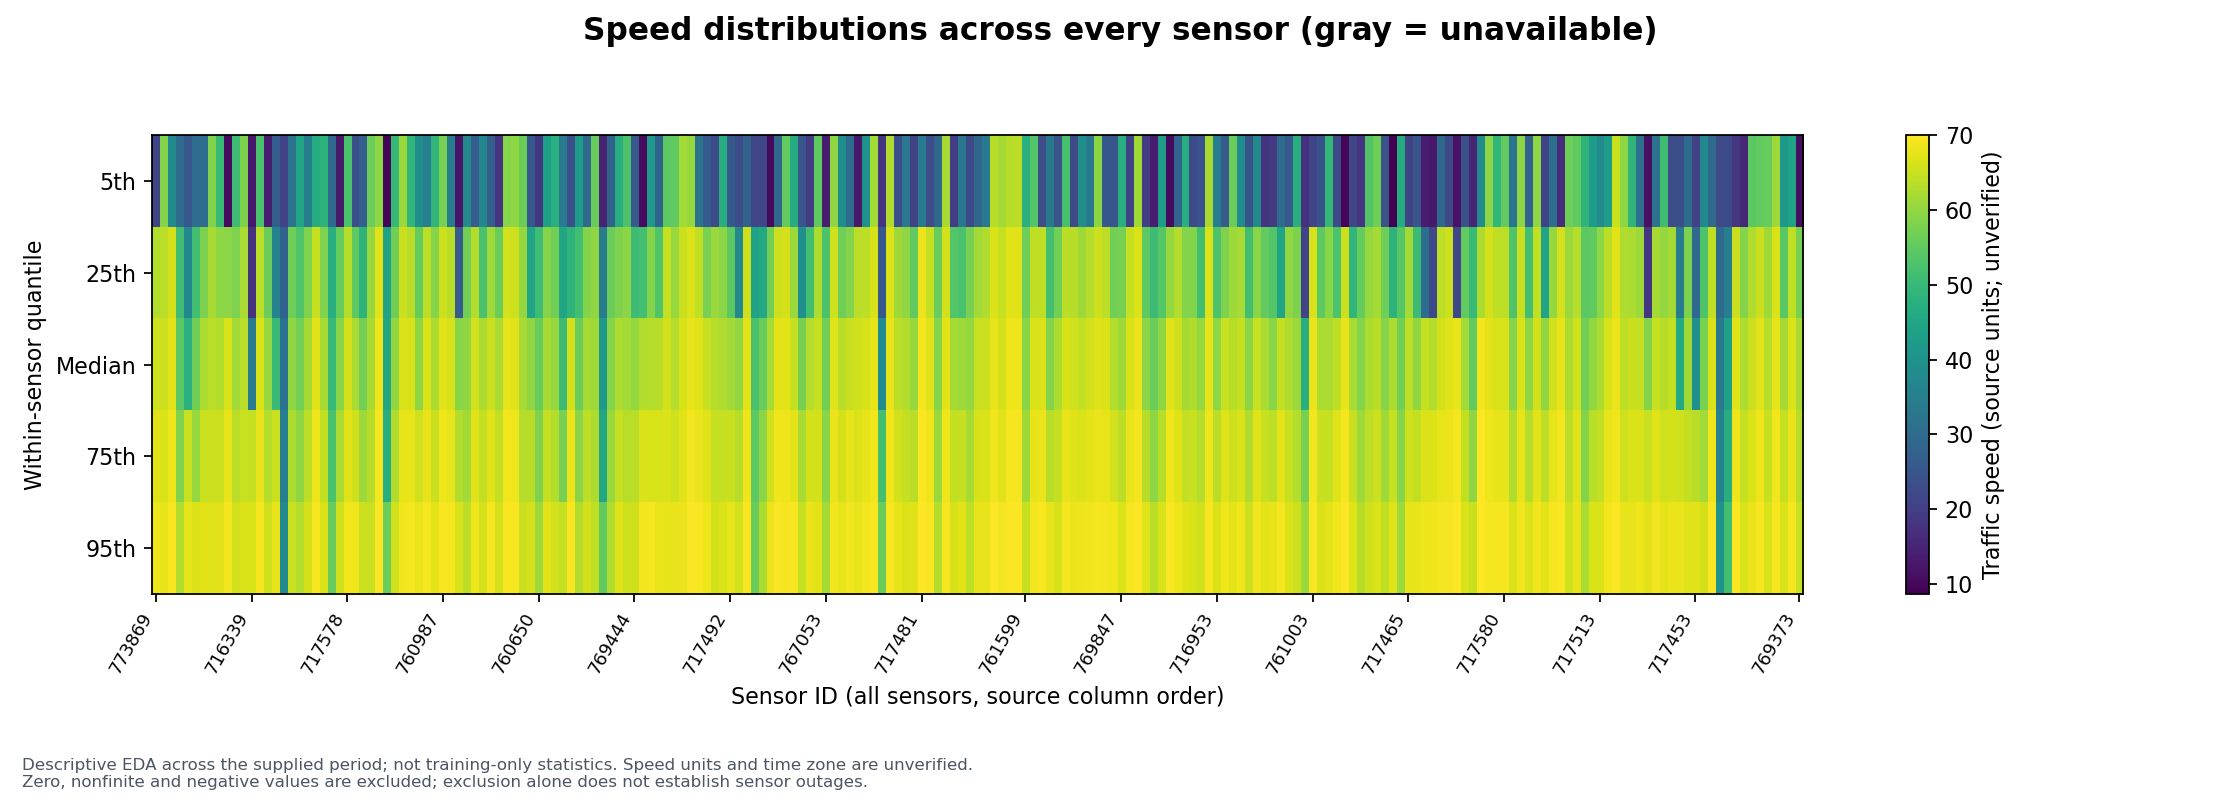

### Average speed by hour

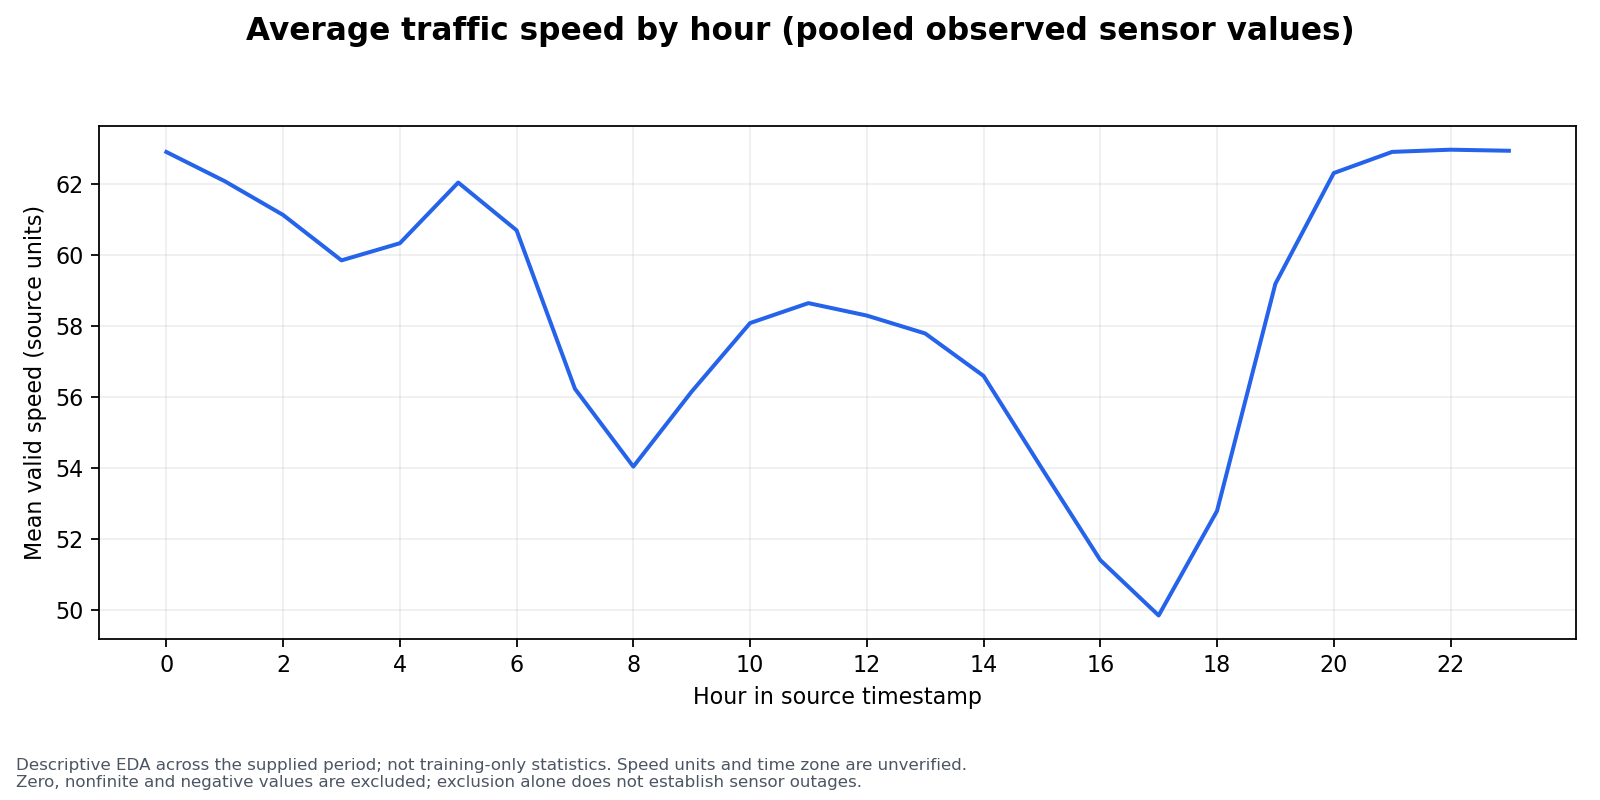

### Average speed by day of week

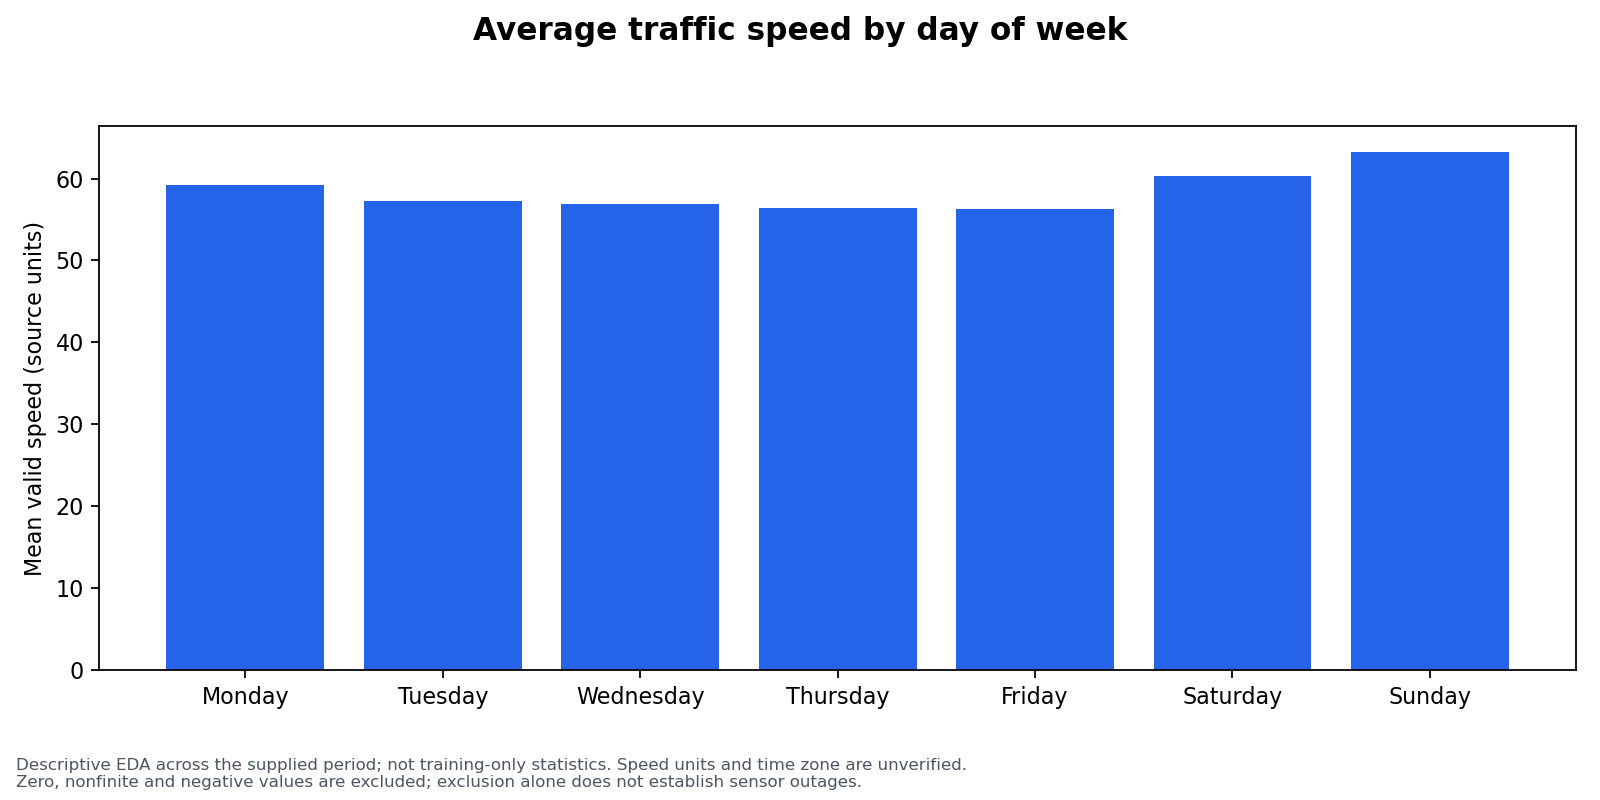

### Weekday weekend profile

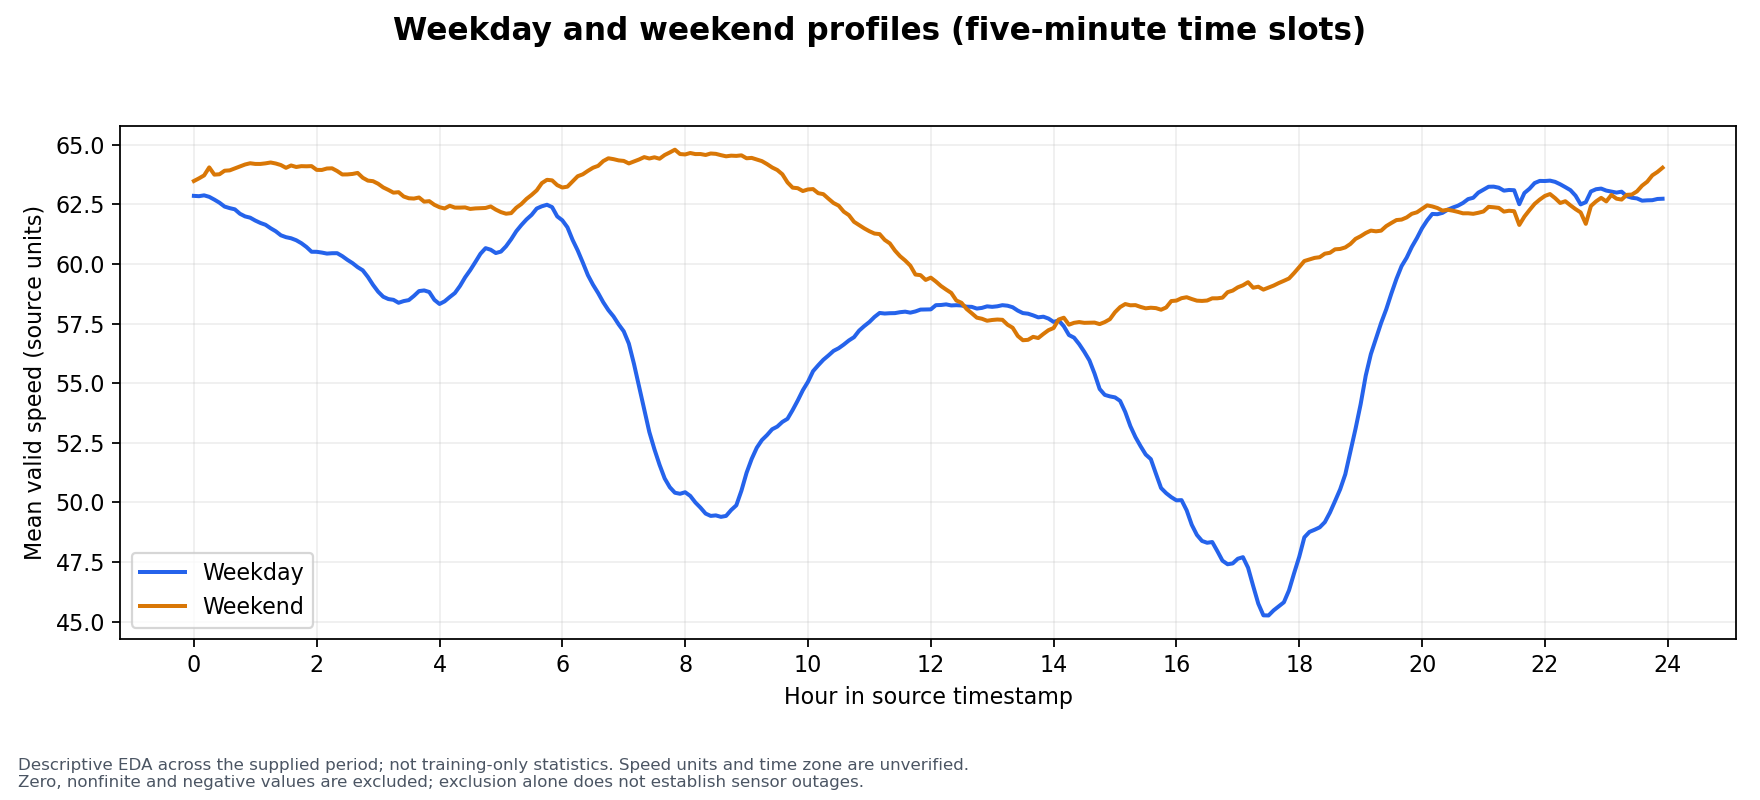

### Morning evening congestion

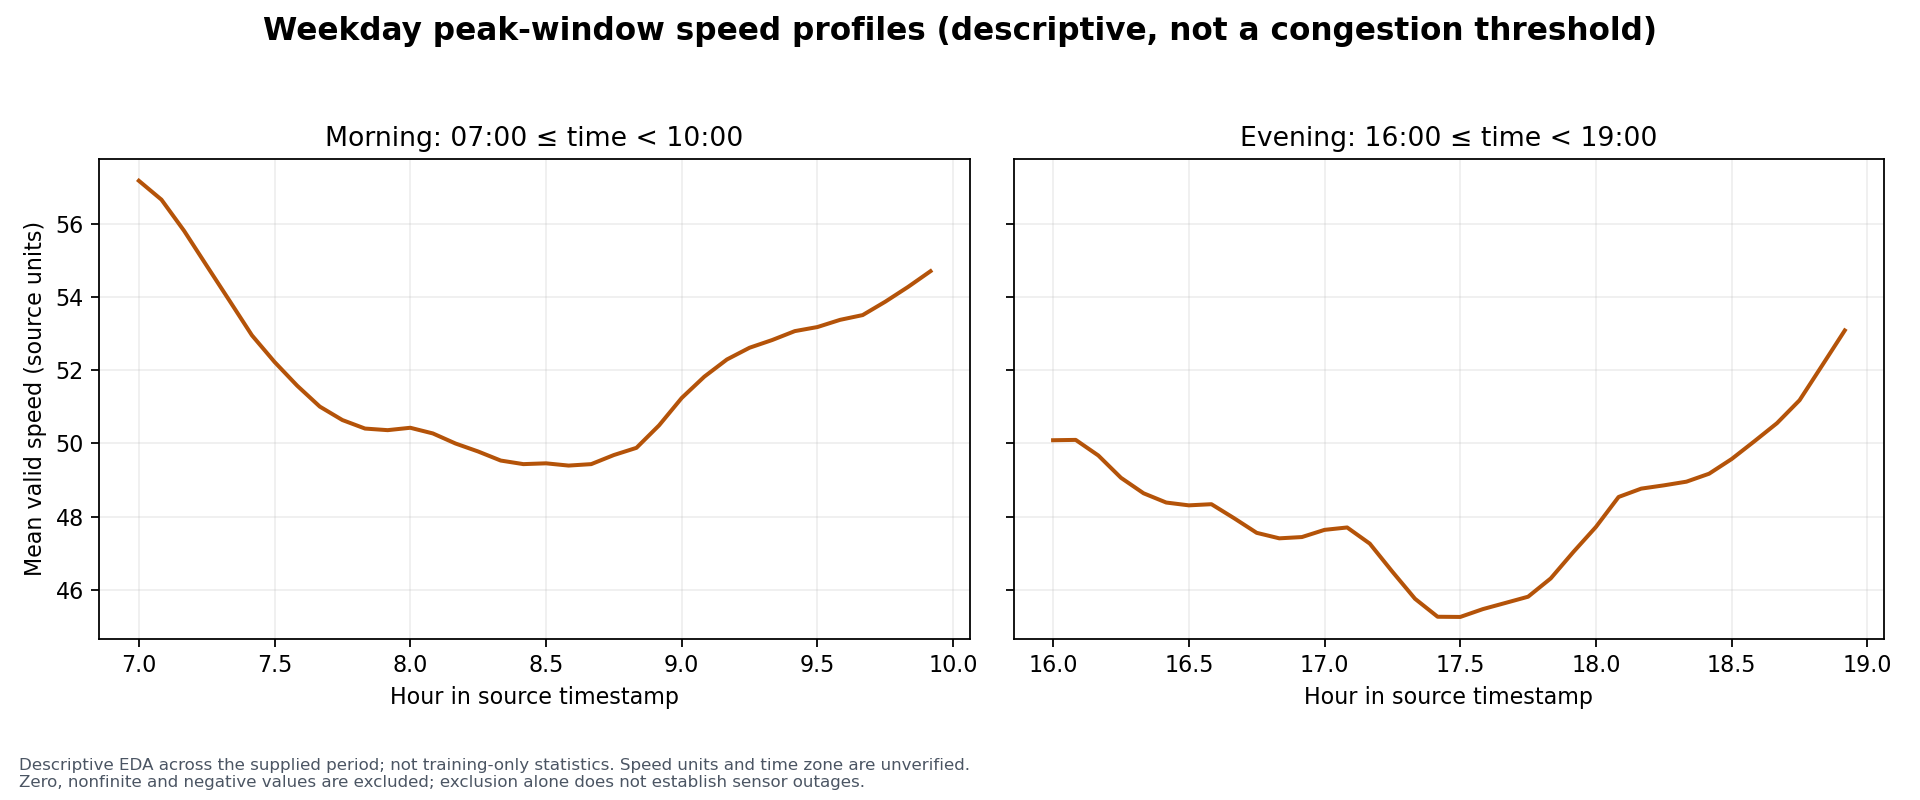

### Missingness by sensor

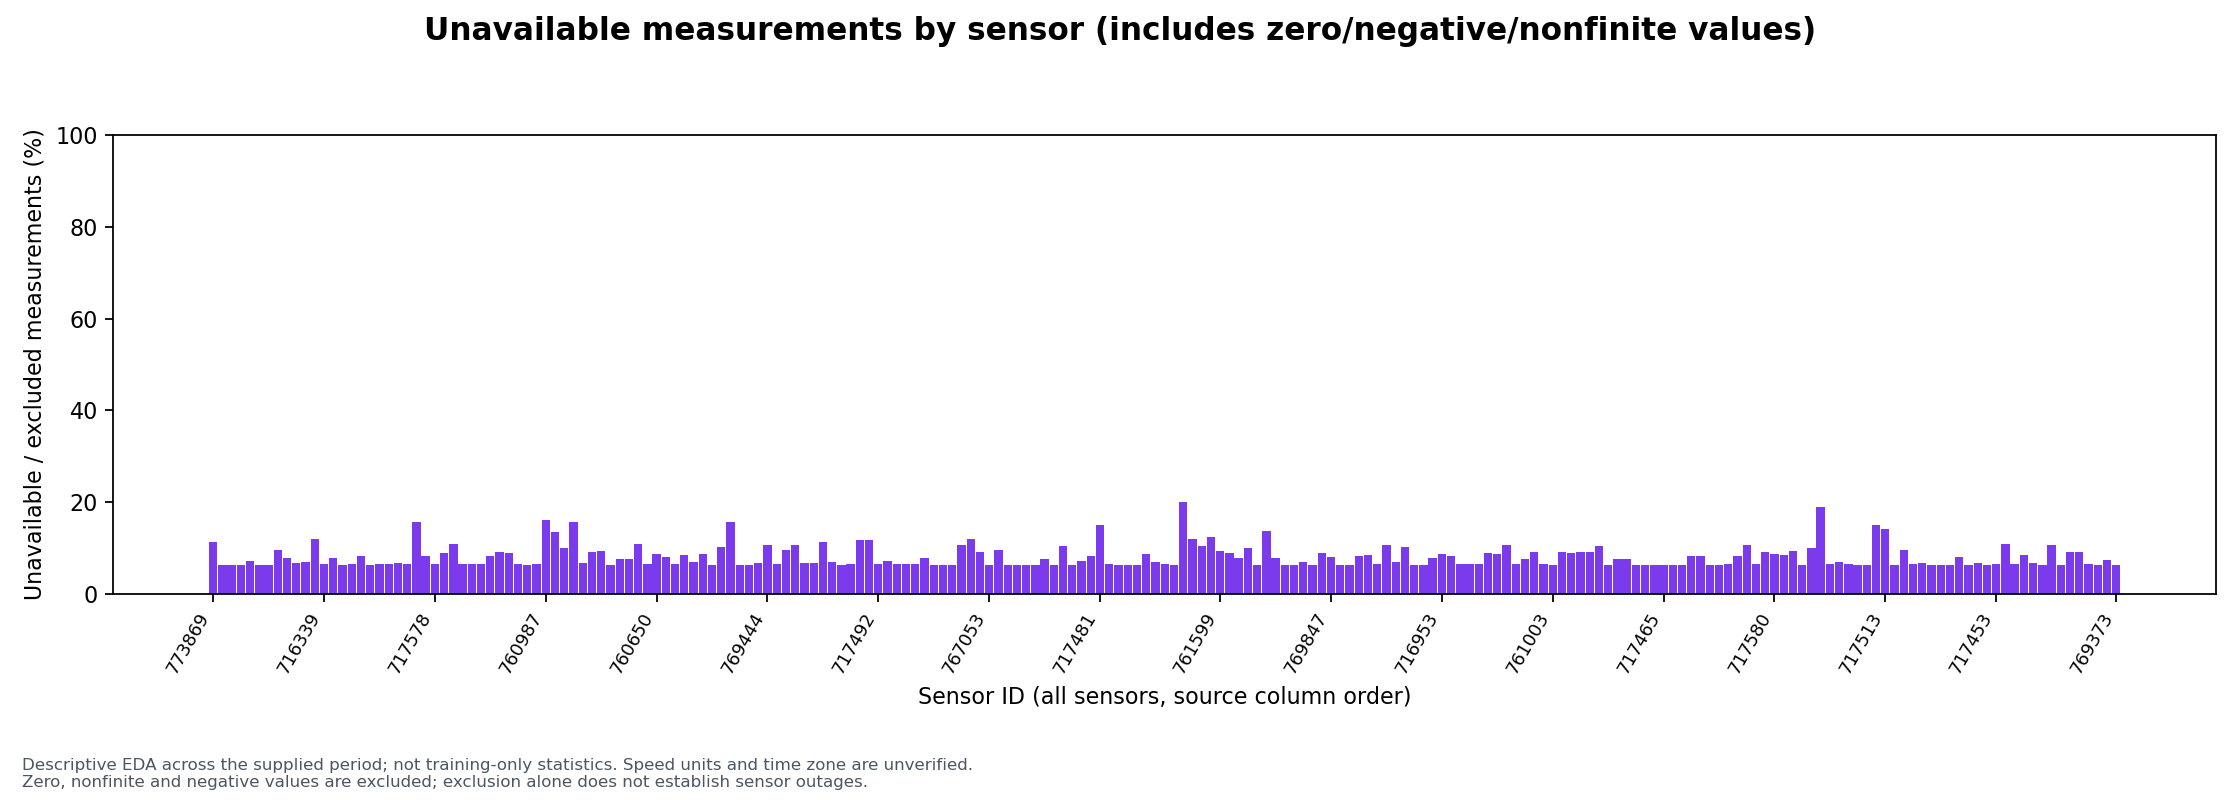

### Missingness over time

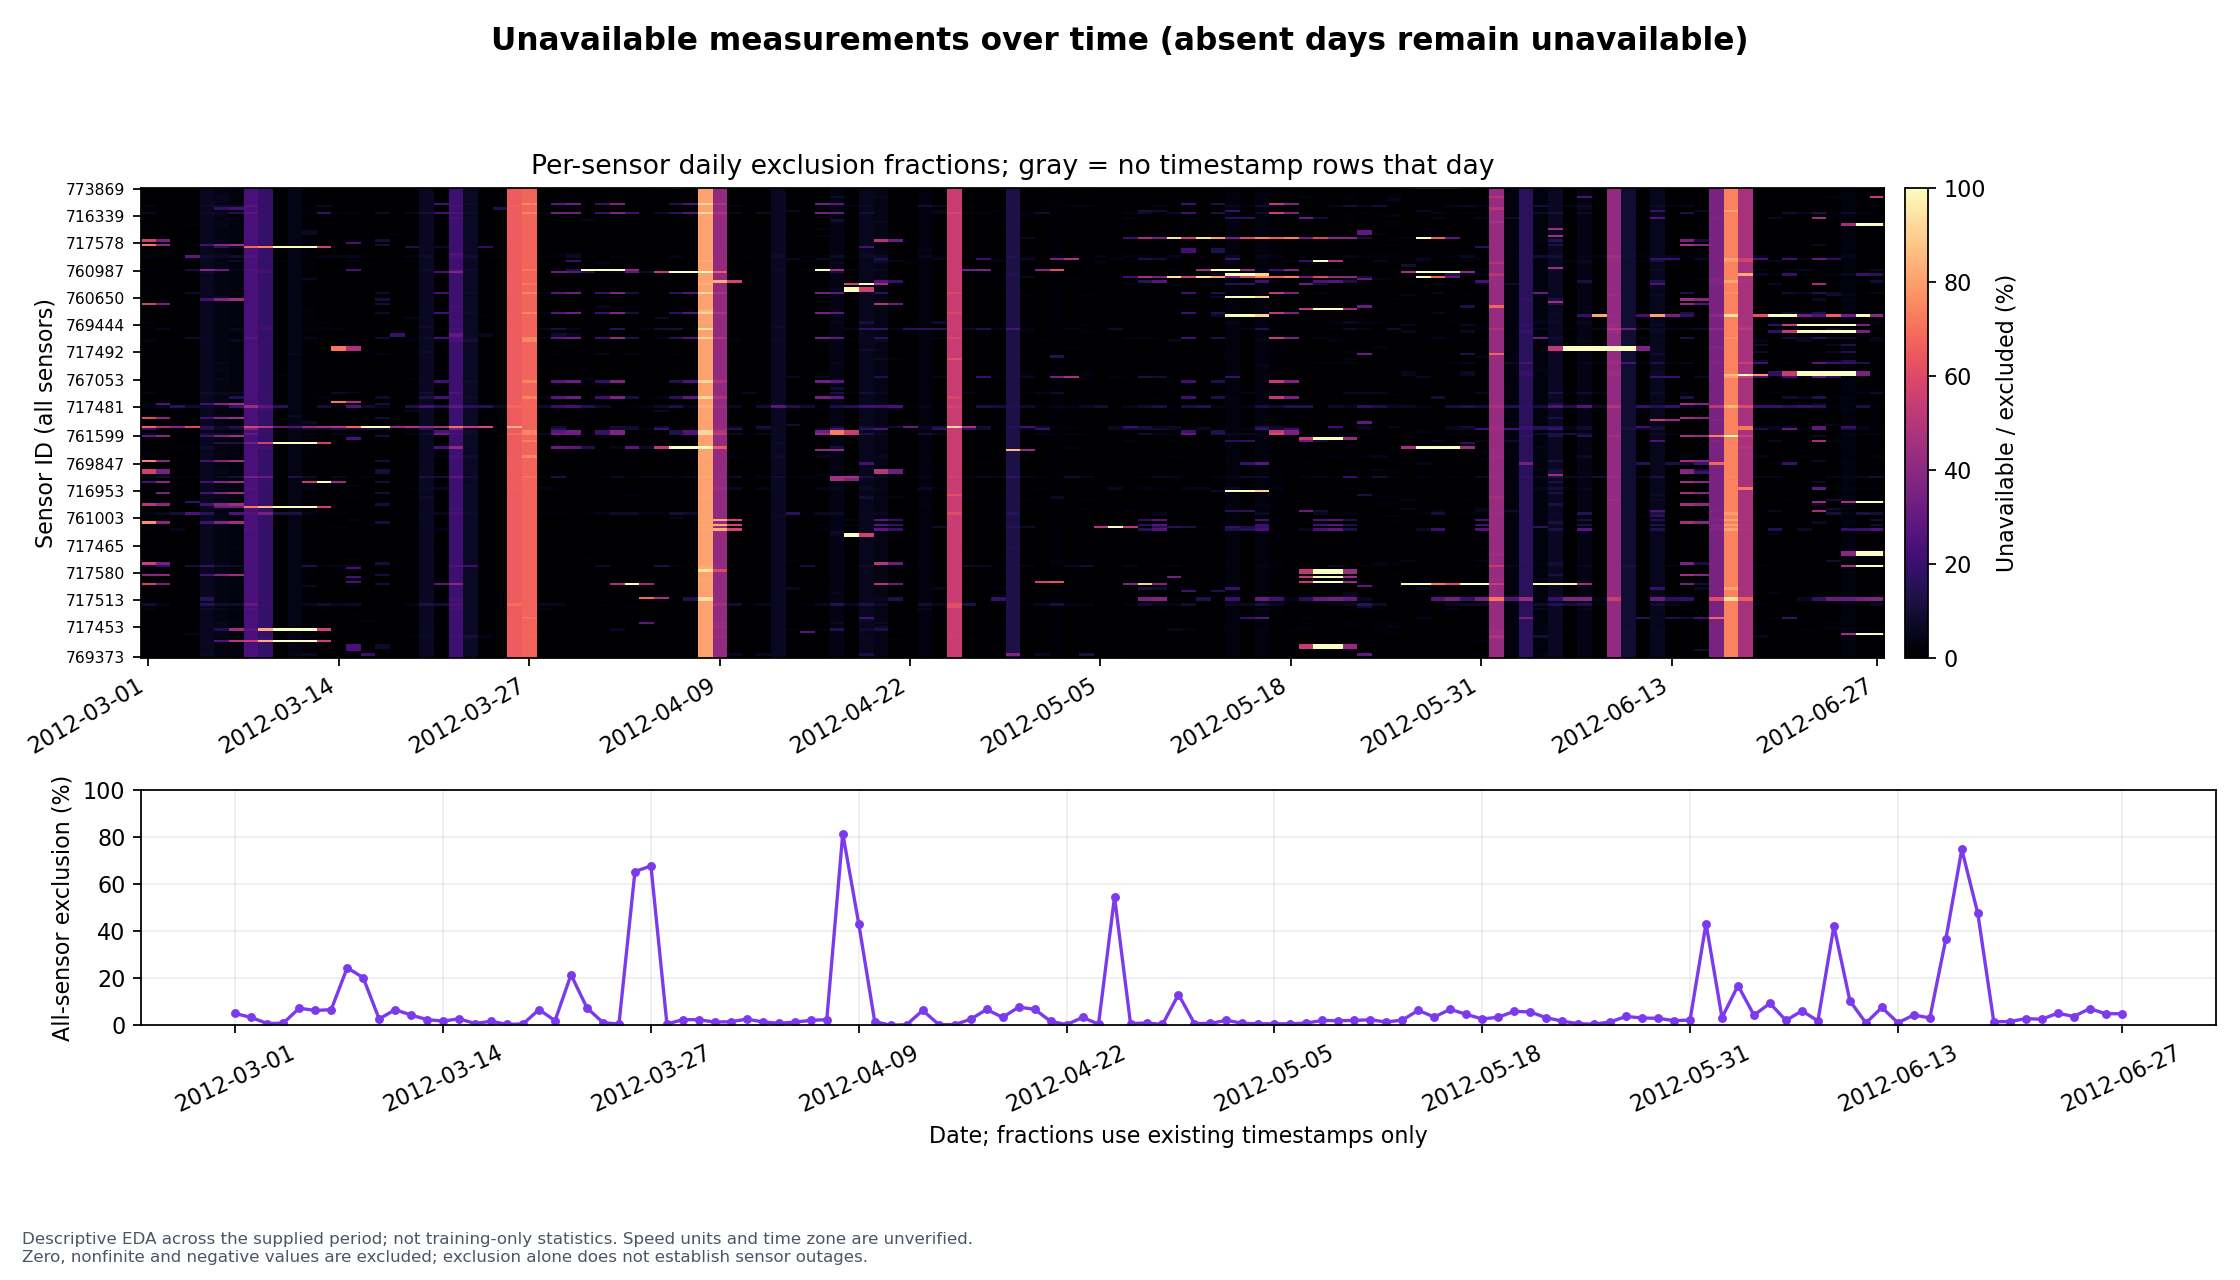

### Sensor variance distribution

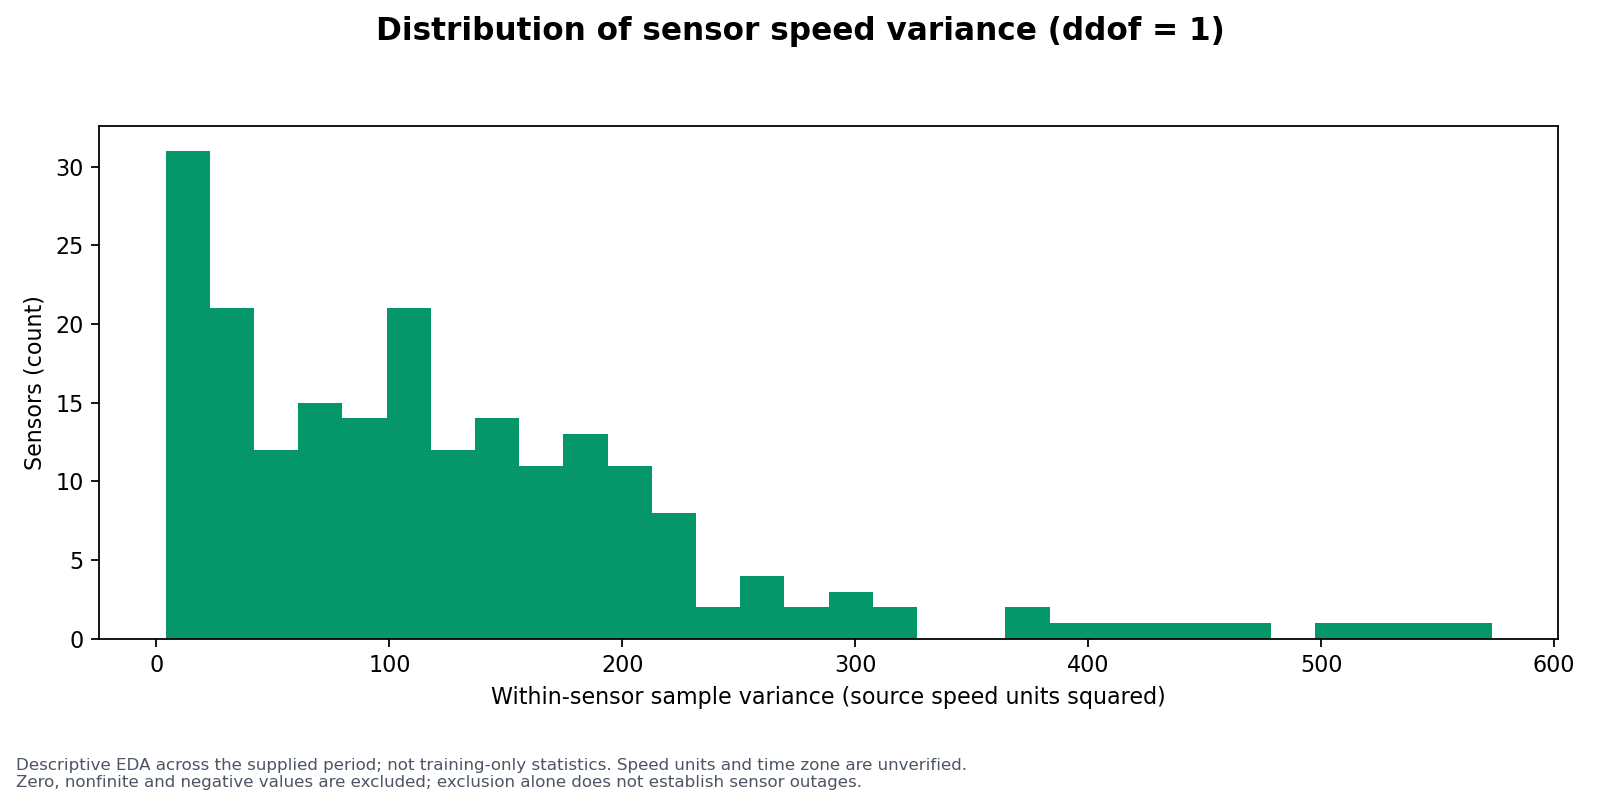

### Sample sensor timeseries

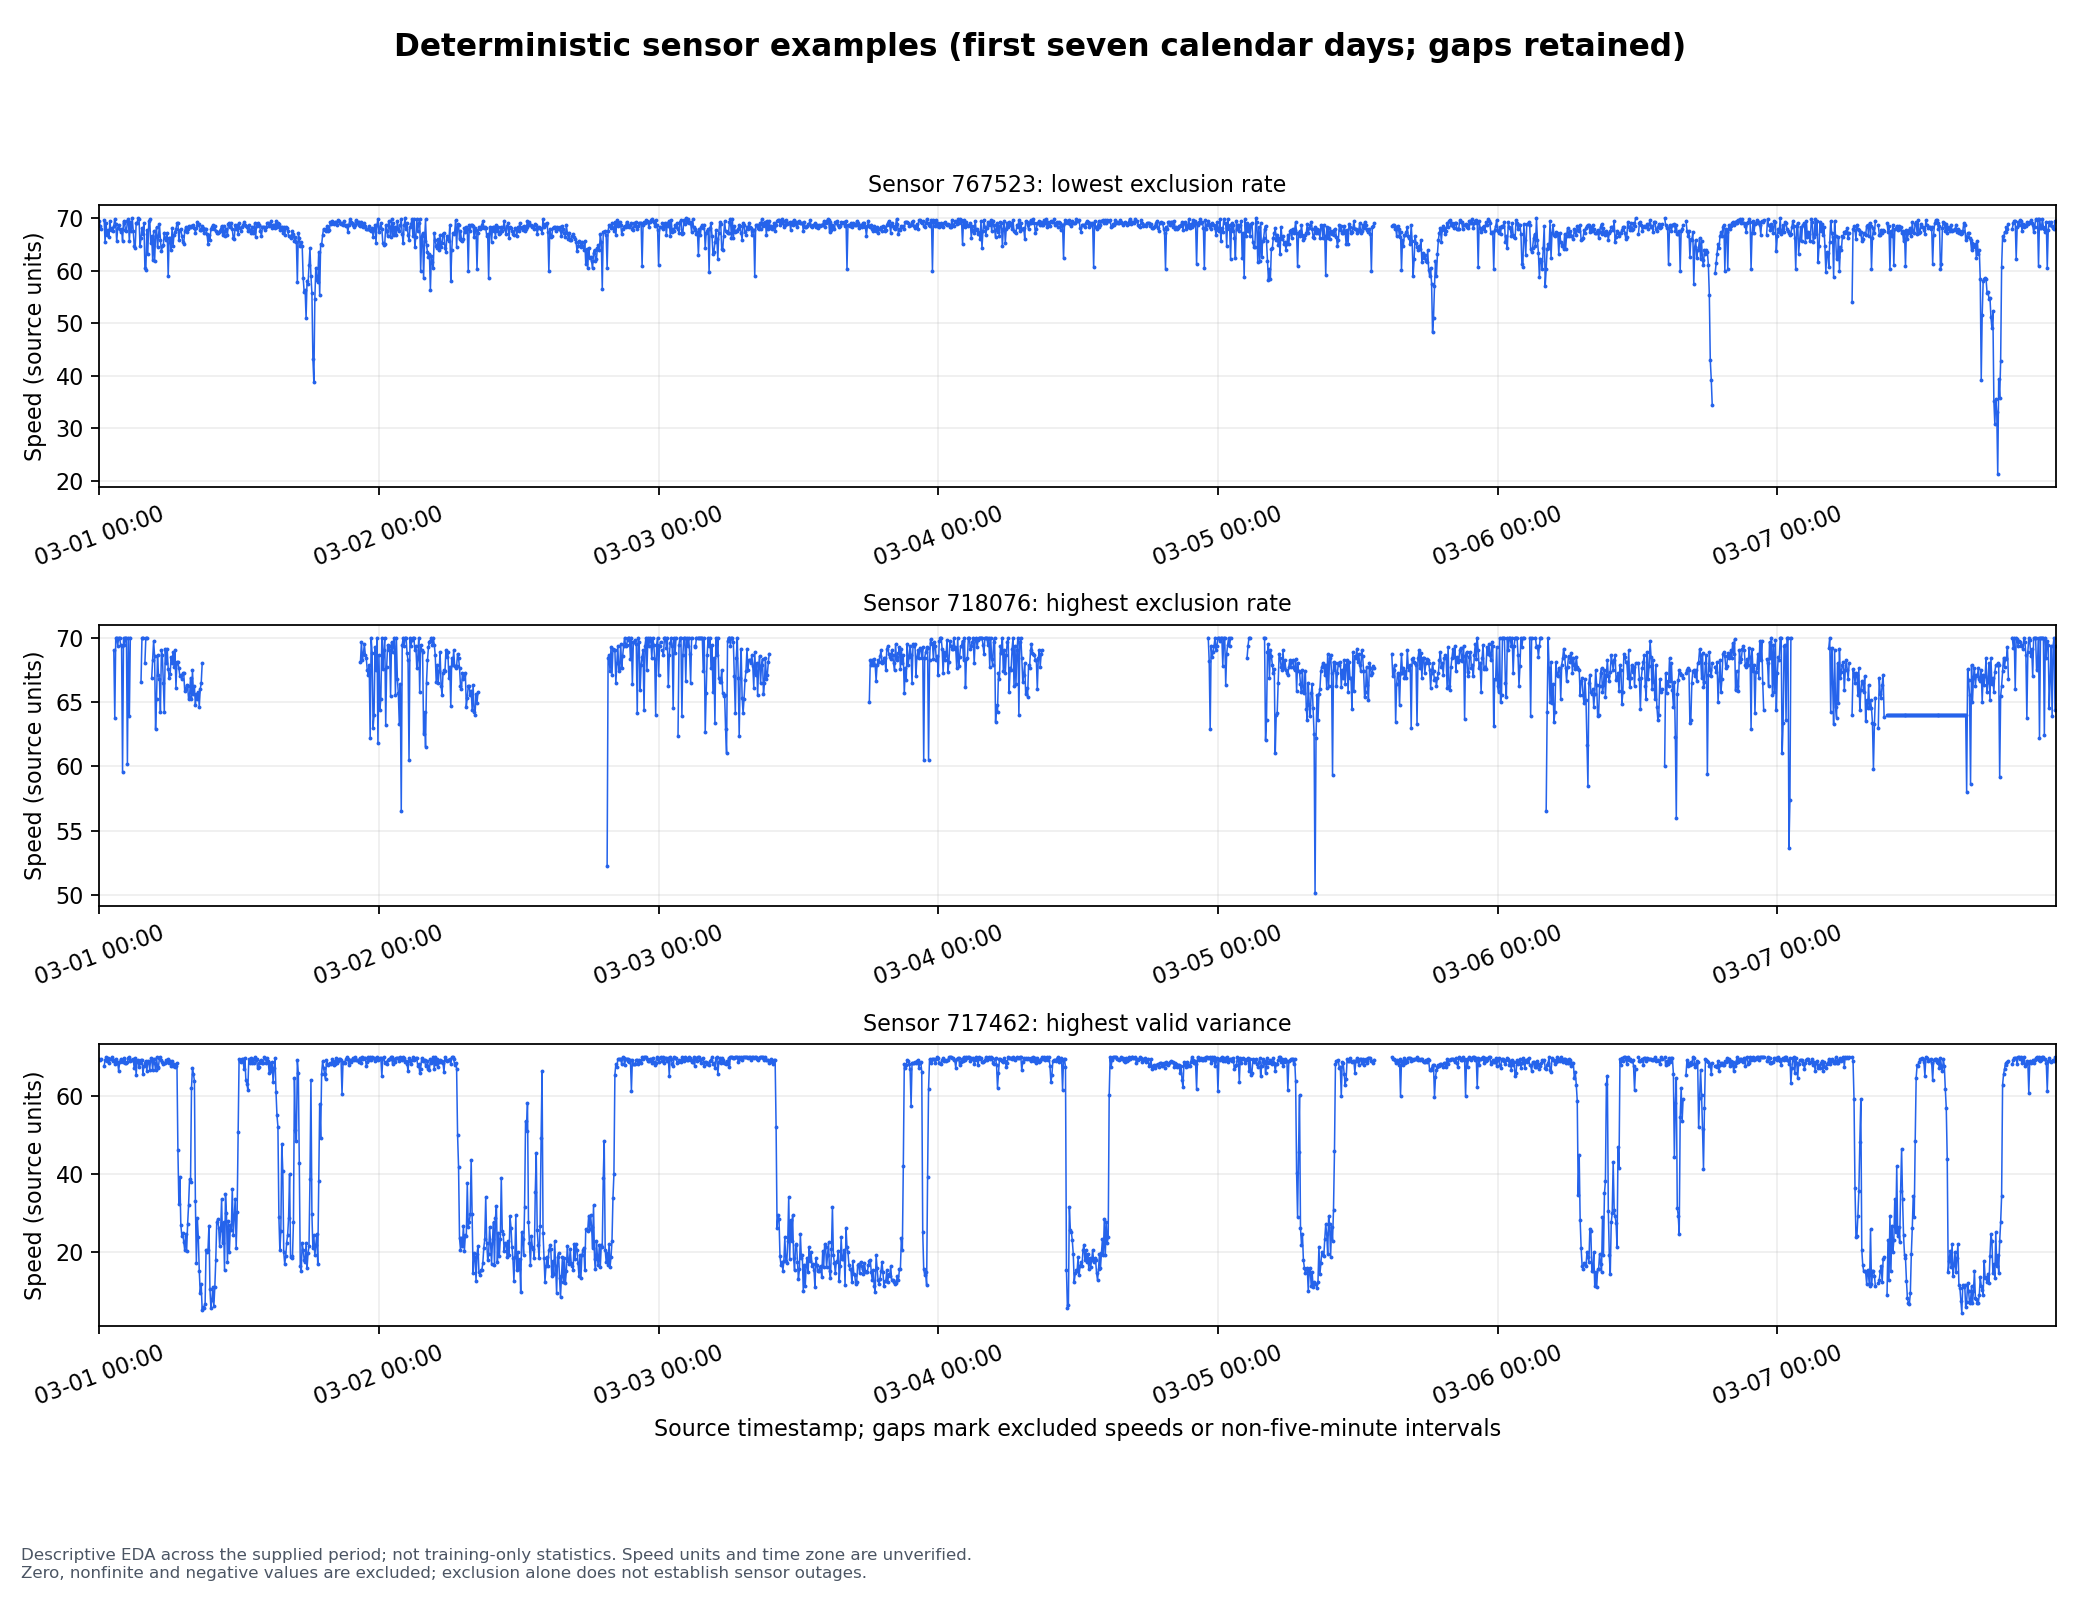

In [6]:
# Display all ten saved PNGs so each can be reviewed in the notebook.
for title, filename in figure_paths.items():
    display(Markdown("### " + title.replace("_", " ").capitalize()))
    display(Image(filename=str(ROOT / "figures" / filename)))

## Sensor summaries and representative examples

Per-sensor statistics below use the valid-speed view. The full sensor distribution figure covers every sensor; the sidecar records deterministic representative selections for descriptive time-series examples. Whole-period representative selection is for plotting only and does not authorize model selection or sensor dropping.

In [7]:
sensor_fields = [
    "sensor_id", "position", "valid_count", "valid_fraction", "valid_mean",
    "valid_std", "valid_min", "valid_median", "valid_max",
]
display(analysis["sensors"][sensor_fields])
selection_path = ROOT / "figures/representative_sensor_selection.csv"
if figure_paths and selection_path.is_file():
    display(pd.read_csv(selection_path, dtype={"sensor_id": str}))

,sensor_id,position,valid_count,valid_fraction,valid_mean,valid_std,valid_min,valid_median,valid_max
0,773869,0,30429,0.887868,61.530971,12.316332,2.500000,65.375000,70.0
1,767541,1,32123,0.937296,64.497026,3.355915,10.875000,65.222222,70.0
2,767542,2,32123,0.937296,64.788643,9.726387,8.111111,67.555556,70.0
3,717447,3,32098,0.936566,52.878571,9.520243,1.000000,54.333333,70.0
4,717446,4,31809,0.928134,49.647798,15.042630,3.000000,47.875000,70.0
...,...,...,...,...,...,...,...,...,...
202,717592,202,31175,0.909635,62.569165,3.575920,2.875000,63.333333,70.0
203,717595,203,32008,0.933940,66.904365,3.500657,6.000000,67.750000,70.0
204,772168,204,32122,0.937267,58.358403,8.363177,2.000000,61.666667,70.0
205,718141,205,31746,0.926296,63.608437,9.737222,5.444444,66.444444,70.0


,sensor_id,sensor_column_position,selection_reasons,unavailable_fraction,valid_sample_variance,display_start,display_end_inclusive,displayed_rows,selection_scope
0,767523,123,lowest_exclusion_rate,0.062675,12.382461,2012-03-01T00:00:00,2012-03-07T23:55:00,2016,whole-period descriptive EDA; not model selection
1,718076,105,highest_exclusion_rate,0.201039,6.553473,2012-03-01T00:00:00,2012-03-07T23:55:00,2016,whole-period descriptive EDA; not model selection
2,717462,163,highest_valid_variance,0.063609,573.117211,2012-03-01T00:00:00,2012-03-07T23:55:00,2016,whole-period descriptive EDA; not model selection


## Interpretation and next step

The measured summary below describes valid positive observations using pooled sensor-cell weighting. Differences in missingness can bias these observed-speed comparisons. These associations do not establish causality or forecast accuracy.

Notebook 02 inspects candidate outages, flatlines and discontinuities and regenerates the quality report and metadata. Person B must retain the documented masks and training-only preprocessing rules.

In [8]:
from src.data.descriptive import summarize_descriptive, render_descriptive
measured_eda = summarize_descriptive(df, analysis)
display(Markdown(render_descriptive(measured_eda["summary"], measured_eda["tables"])))

## Measured descriptive findings

The source covers **2012-03-01T00:00:00 through 2012-06-27T23:55:00**, with 34,272 timestamps and 207 sensors. Speeds use unverified source units. Calendar groups use the stored clock; no timezone is inferred or converted.

Across **6,519,002 valid positive sensor cells**, mean speed is **58.46**, median **63.22**, and the 5th–95th percentile range is **25.62–68.89**.

Excluded readings total **575,302 / 7,094,304 (8.11%)**; exact zeros account for 575,302. Positive near-zero speeds remain observed. No imputation or trained preprocessing is performed.

Hourly pooled means are lowest at stored hour **17:00 (49.85)** and highest at **22:00 (62.96)**. Daily pooled means are lowest on **Friday (56.32)** and highest on **Sunday (63.21)**.

All temporal means pool valid sensor cells using their counts. They are descriptive associations; unavailable readings may be nonrandom, so these profiles can be biased. Counts and exclusion rates accompany the means.

### Weekday and weekend observations

| day type | Valid cells | Mean speed | Excluded (%) |
| --- | --- | --- | --- |
| Weekday | 4690209 | 57.20 | 7.44 |
| Weekend | 1828793 | 61.68 | 9.78 |

### Traffic-period observations

| period | Valid cells | Mean speed | Excluded (%) |
| --- | --- | --- | --- |
| Weekday morning peak | 574372 | 52.02 | 9.32 |
| Weekday evening peak | 597567 | 48.25 | 5.66 |
| Weekday off-peak | 3518270 | 59.57 | 7.43 |
| Weekend | 1828793 | 61.68 | 9.78 |

Peak windows are weekdays [07:00, 10:00) and [16:00, 19:00); weekday off-peak excludes both windows. Weekend observations are reported separately. Full hourly and day-of-week tables are exported alongside these tables.

### Strongest zero-value evidence

All 207 sensors are zero together in **2,148 timestamp rows (6.27%)**, forming **97** consecutive five-minute blocks. Gaps and duplicate timestamps interrupt blocks.

These simultaneous-zero rows account for **77.2874%** of all exact-zero sensor cells.

The longest simultaneous-zero block has **381 slots**, from **2012-03-26T08:25:00** through **2012-03-27T16:05:00** (1,905 minutes of five-minute slots; the elapsed first-to-last span is one slot shorter).

Sensors with the highest zero rates:

| Sensor | Zero cells | Zero (%) |
| --- | --- | --- |
| 718076 | 6890 | 20.10 |
| 716939 | 6464 | 18.86 |
| 760987 | 5532 | 16.14 |

Longest individual zero runs (slot duration includes all observed five-minute slots):

| sensor_id | position | start_timestamp | end_timestamp | length | duration_minutes | possible_outage |
| --- | --- | --- | --- | --- | --- | --- |
| 717490 | 70 | 2012-06-05 12:25:00 | 2012-06-11 08:35:00 | 1683 | 8,415.00 | True |
| 717491 | 71 | 2012-06-05 12:25:00 | 2012-06-11 08:35:00 | 1683 | 8,415.00 | True |
| 769444 | 60 | 2012-06-21 17:35:00 | 2012-06-26 08:20:00 | 1330 | 6,650.00 | True |

Simultaneous zeros and long zero runs are evidence for investigating unavailable measurements. They do not establish a physical cause or prove an outage. Raw values are preserved, exact zeros are flagged as benchmark missing/suspect, and no sensor is automatically removed.
